# [Lab Session 3](fourier.ipynb)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.transform import resize

**[Task 1 (a).]()** Load the first image, resize it to (256, 256) and display it.


In [2]:
cell_img = plt.imread('data/cells.png')

In [3]:
cell_img_r = resize(cell_img, (256, 256))

plt.figure()
plt.imshow(cell_img_r, cmap="gray")
plt.colorbar()

**[Task 1 (b).]()** Apply the fast Fourier transform and check the data type of the result.


complex128


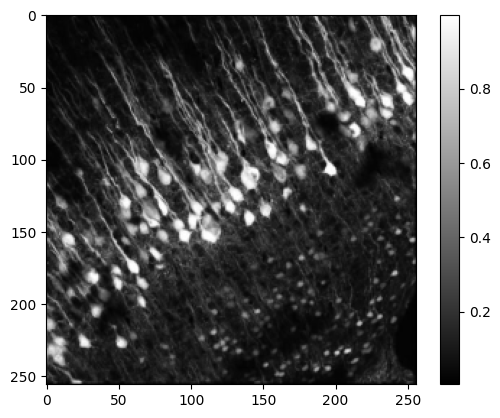

In [4]:
cell_ft = np.fft.fft2(cell_img_r)
print(cell_ft.dtype)

**[Task 1 (c).]()** Extract the phase and amplitude and display them.


In [5]:
amplitude = np.abs(cell_ft)
phase = np.angle(cell_ft)

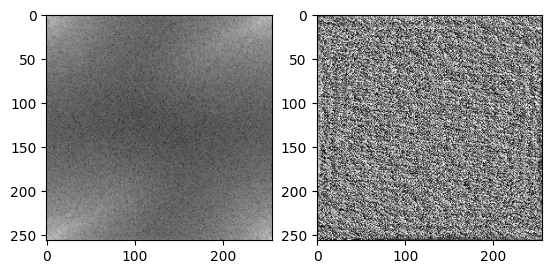

In [6]:
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

**[Task 1 (d).]()** Do a shift so that zero is displayed in the center of the image and show amplitude and phase again.


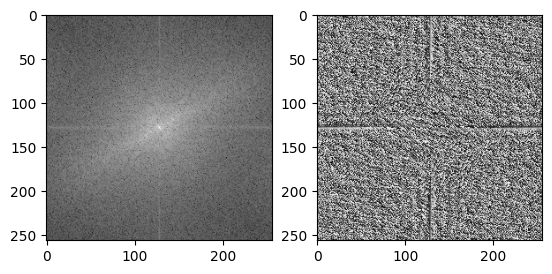

In [7]:
cell_ft_shift = np.fft.fftshift(cell_ft)

amplitude_shift = np.abs(cell_ft_shift)
phase_shift = np.angle(cell_ft_shift)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude_shift), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase_shift, 'gray')

**[Task 1 (e).]()** Apply the inverse FFT and display the restored image.


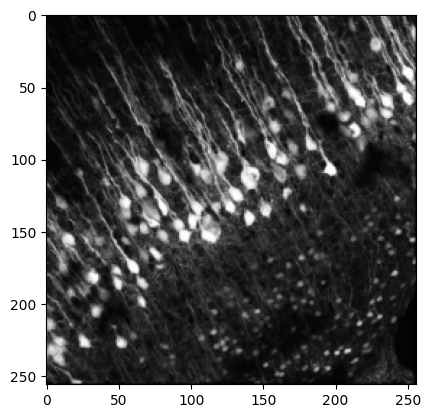

In [8]:
cell_restored = np.fft.ifft2(np.fft.ifftshift(cell_ft_shift))

plt.figure()
plt.imshow(cell_restored.real, "gray")

---


**[Task 2 (a).]()** Load the brain MR image.


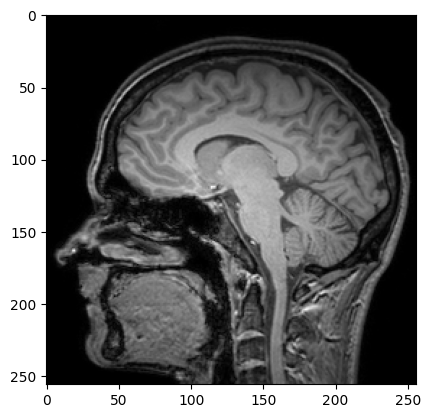

In [9]:
brain_mri = resize(plt.imread("data/brain_mri.png"), (256, 256))

plt.figure()
plt.imshow(brain_mri, "gray")

**[Task 2 (b).]()** Apply the FFT, do a shift, extract amplitude and phase.


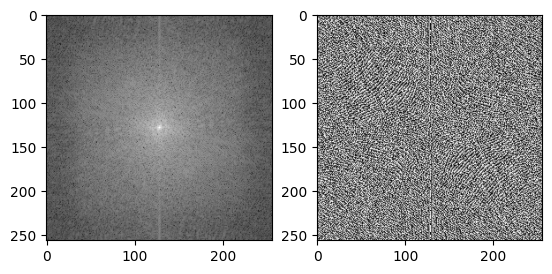

In [10]:
brain_ft = np.fft.fft2(brain_mri)

brain_ft_shift = np.fft.fftshift(brain_ft)

amplitude_brain_shift = np.abs(brain_ft_shift)
phase_brain_shift = np.angle(brain_ft_shift)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude_brain_shift), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase_brain_shift, 'gray')

In [11]:
def to_complex_array(amplitude_array, phase_array):
    return amplitude_array * np.exp(1j * phase_array)

**[Task 2 (c).]()** Merge the amplitude of the brain MR image and the phase of cell image. Do the IFFT and display the resulting image.


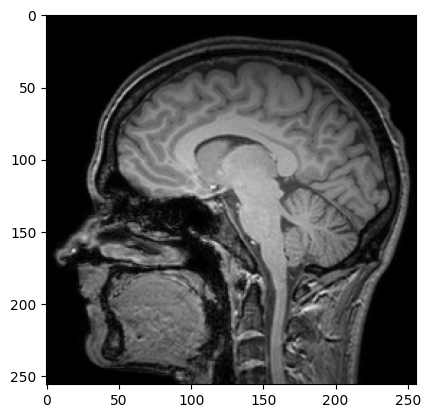

In [12]:
brain_restore = np.fft.ifft2(np.fft.ifftshift(to_complex_array(amplitude_brain_shift, phase_brain_shift)))

plt.figure()
plt.imshow(brain_restore.real, "gray")

**[Task 2 (d).]()** Repeat this with the amplitude of the cells and the phase of the brain.


In [13]:
print(amplitude.shape)
print(phase_brain_shift.shape)

(256, 256)
(256, 256)


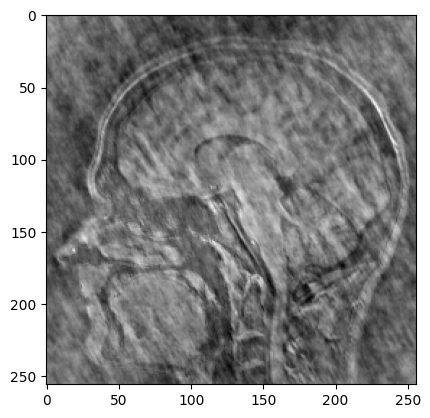

In [14]:
brain_cell_restore = np.fft.ifft2(np.fft.ifftshift(to_complex_array(amplitude_shift, phase_brain_shift)))

plt.figure()
plt.imshow(brain_cell_restore.real, "gray")

It seems that the phase contains more information, because the image of the brain is still clearly visible even though the amplitude of the cell image was used.

---


**[Task 3 (a).]()** Create a lowpass filter mask.


In [15]:
filter_window_size = 50

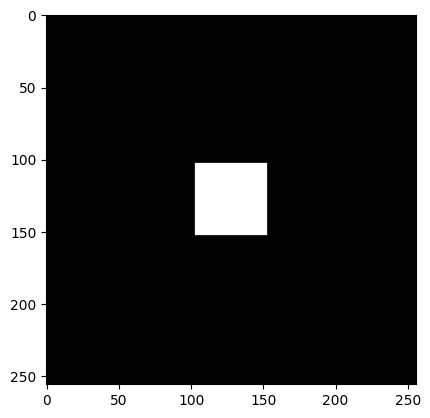

In [16]:
filter_mask_low = resize(np.array([0]), (256, 256))

filter_mask_low[103:153, 103:153] = 1

plt.figure()
plt.imshow(filter_mask_low, "gray")

**[Task 3 (b).]()** Create a highpass filter maks.


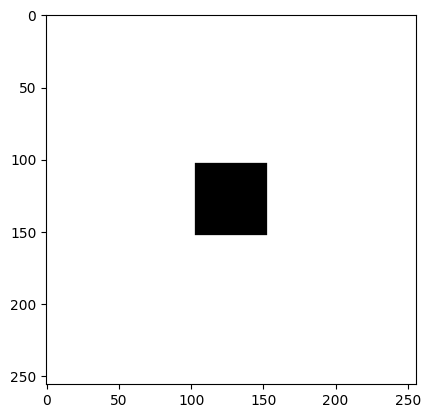

In [17]:
filter_mask_high = 1 - filter_mask_low

plt.figure()
plt.imshow(filter_mask_high, "gray")

**[Task 3 (c).]()** Apply the lowpass and highpass filter mask to the amplitude of the brain and display the results.


/tmp/ipykernel_42786/217125461.py:8: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(amplitude_brain_low), "gray")
/tmp/ipykernel_42786/217125461.py:10: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(amplitude_brain_high), "gray")


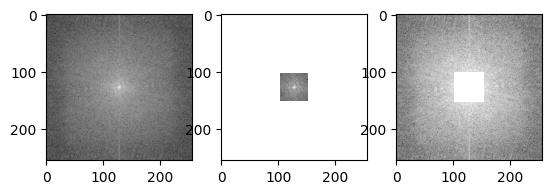

In [18]:
amplitude_brain_low = filter_mask_low * amplitude_brain_shift
amplitude_brain_high = filter_mask_high * amplitude_brain_shift

plt.figure()
plt.subplot(1, 3, 1)
plt.imshow(np.log(amplitude_brain_shift), "gray")
plt.subplot(1, 3, 2)
plt.imshow(np.log(amplitude_brain_low), "gray")
plt.subplot(1, 3, 3)
plt.imshow(np.log(amplitude_brain_high), "gray")

**[Task 3 (d).]()** Apply the mask to the amplitude, merge the result with the phase and restore the image.


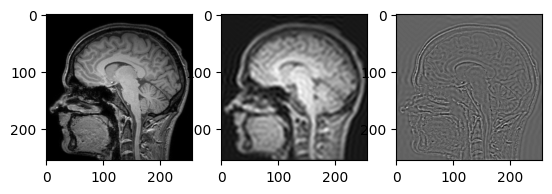

In [19]:
brain_low = np.fft.ifft2(np.fft.ifftshift(to_complex_array(amplitude_brain_low, phase_brain_shift)))
brain_high = np.fft.ifft2(np.fft.ifftshift(to_complex_array(amplitude_brain_high, phase_brain_shift)))

plt.figure()
plt.subplot(1, 3, 1)
plt.imshow(brain_mri, "gray")
plt.subplot(1, 3, 2)
plt.imshow(brain_low.real, "gray")
plt.subplot(1, 3, 3)
plt.imshow(brain_high.real, "gray")

---


**[Task 4 (a).]()** Implement a function that computes the 2D-DFT.


In [53]:
def twod_dft(img) :
    dft = np.zeros(img.shape, dtype=complex)
    M, N = img.shape
    for u in range(M) :
        for v in range(N) :
            s = []
            for x in range(M) :
                for y in range(N) :
                    s.append(img[x, y] * np.exp(-2*1j*np.pi*(((x+1)*(u+1) / (M)) + ((y+1)*(v+1) / (N)))))

            dft[u, v] = (1 / (M) * (N)) * sum(s)
    return dft

**[Task 4 (b).]()** Implement a function that computes the 2D-IDFT.


In [54]:
def inverse_dft(dft) :
    idft = np.zeros(dft.shape, dtype=complex)
    M, N = dft.shape
    for u in range(M) :
        for v in range(N) :
            s = []
            for x in range(M) :
                for y in range (N) :
                    s.append(dft[x,y] * np.exp(2*1j*np.pi*(((x+1) * (u+1) / (M)) + ((y+1) * (v+1) / (N)))))
            idft[u, v] = sum(s)
    return idft

Due to high computational costs, we need to resize the image.


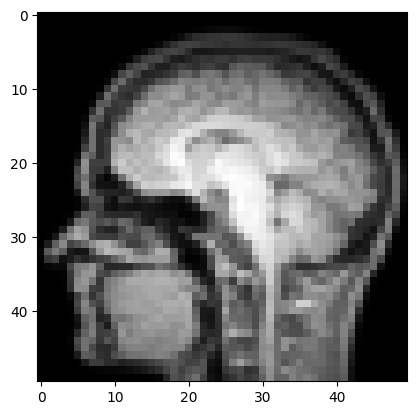

In [37]:
test_img = resize(brain_mri, (50, 50))
plt.imshow(test_img, 'gray')

**[Task 4 (c).]()** Apply your DFT implementation to the image and display amplitude and phase.


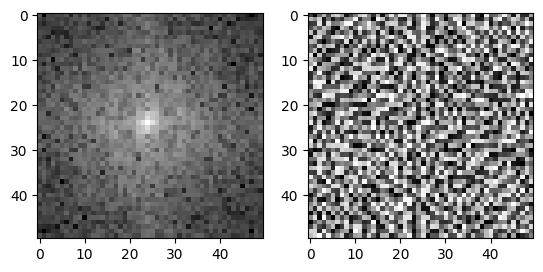

In [55]:
brain_ft_test = twod_dft(test_img)

brain_ft_test_shift = np.fft.fftshift(brain_ft_test)

amplitude_brain_shift_test = np.abs(brain_ft_test_shift)
phase_brain_shift_test = np.angle(brain_ft_test_shift)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude_brain_shift_test), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase_brain_shift_test, 'gray')

**[Task 4 (d).]()** Reconstruct the image using your IDFT implementation and display it.


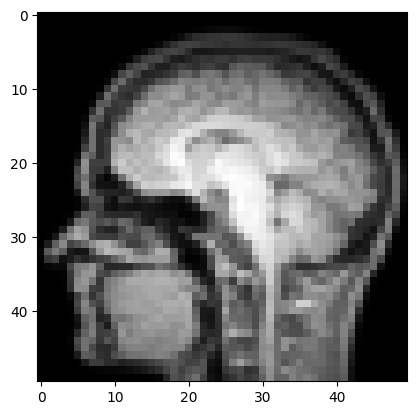

In [56]:
brain_test_restore = inverse_dft(np.fft.ifftshift(to_complex_array(amplitude_brain_shift_test, phase_brain_shift_test)))

plt.figure()
plt.imshow(brain_test_restore.real, "gray")

**[Task 4 (e).]()** Compare your result to the result of numpy's FFT


In [58]:
np.allclose(twod_dft(test_img), np.fft.fft2(test_img, norm="forward"))

False

**[Task 4 (f).]()** Round the arrays and compare them again.


In [59]:
np.mean(np.abs(twod_dft(test_img) - np.fft.fft2(test_img, norm="forward")))

3.9991740846509334

In [63]:
test_dft = twod_dft(test_img)
numpy_fft = np.fft.fft2(test_img, norm="forward")

In [65]:
(np.round(test_dft, 1) == np.round(numpy_fft, 1)).all()

False

**[Task 4 (g).]()** Compare the run times of the two algorithms (your DFT and numpy's FFT)
